In [1]:
import sys
import os
import matplotlib.pyplot as plt
import matplotlib.pyplot as plt
import numpy as np
import torch
import random
import torch.nn.functional as F

In [2]:
np.random.seed(0)
torch.manual_seed(0)
random.seed(0)

In [3]:
def read_parameters(file_path):
    params = {}

    # First pass: read and store values as strings
    with open(file_path, 'r') as file:
        for line in file:
            # Skip empty lines and comments (if any)
            line = line.strip()
            if line and not line.startswith('#'):
                # Split the line at the equals sign
                key, value = line.split('=')
                key = key.strip()
                value = value.strip()

                # Store the parameter as a string for now
                params[key] = value

    # Second pass: evaluate expressions and convert values
    for key, value in params.items():
        try:
            # Try to evaluate the value as a Python expression using previously defined parameters
            params[key] = eval(value, {}, params)
        except:
            # If it's not an expression, check if it can be converted to float or int
            if '.' in value:
                params[key] = float(value)
            else:
                params[key] = int(value)
        
        # Set the variable in the global namespace with the evaluated value
        globals()[key] = params[key]

    return params

In [4]:
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), "..")))
from ants_move import *
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), "../../../..")))

pygame 2.6.1 (SDL 2.28.4, Python 3.13.3)
Hello from the pygame community. https://www.pygame.org/contribute.html


/home/alepitt/phd/pytorch_DGN/.venv/lib/python3.13/site-packages/pygame/pkgdata.py:25: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_stream, resource_exists


In [5]:
work_folder = 'edge_spen'
saving_folder = 'l0'
os.chdir(work_folder)

In [6]:
file_path = saving_folder + '/parameters.txt'  # Path to the parameters file
parameters = read_parameters(file_path)

for key, value in parameters.items():
    print(f"{key} = {value}")

n = 300
Lx = 32
Ly = 32
delta = [0.3, 0.4, 0.5, 0.6, 0.7, 0.8]
beta = [3.5, 4.5, 5.5, 6.5, 7.5, 8.5, 9.5]
eta = 0.01
decay_rate = 0.015
eta_special = 1
n_special = 30
t_transient = 200
tmax = 1200
batch_size = 60
gamma = 0.99
state_dim = (4, 9, 9)
action_dim = 8
action_bound = 1
vision = 9
actor_lr = 5e-06
critic_lr = 5e-05
weight_decay = 0.0
clip_epsilon = 0.2
entropy_coeff = 0.05
policy_steps = 1000
learning_steps = 1
clip_grad = False
use_gae = True
lam = 0.95


In [7]:
def beta_crit(d, s0):
    return 1 + 1/s0 + 2*d + d*s0 + d**2*s0

s0 = (n*eta + n_special*eta_special)/(decay_rate*Lx**2)
print(s0)

2.1484375


In [8]:
vision=state_dim[-1]
from ppo_ants import *

In [9]:
def setup_environment(n, Lx, Ly, delta, beta, decay_rate, eta, eta_special,
                        tmax, n_special, t_transient, vision,
                        gamma, action_bound, actor_lr, critic_lr, batch_size, weight_decay,
                        clip_epsilon, entropy_coeff, policy_steps, learning_steps,
                        state_dim, action_dim, clip_grad):
    
    env = Ants(n, Lx, Ly, delta, beta, decay_rate, eta, eta_special,
            tmax, n_special, t_transient, vision=state_dim[-1])
    
    sys.path.append(os.path.abspath(os.path.join(os.getcwd(), "../../../..")))

    config_net_file = f"{saving_folder}/networks.yaml"
    ppo_ants = PPO_ants( env,
                    gamma, action_bound, actor_lr, critic_lr, batch_size, weight_decay, config_net_file,
                    clip_epsilon, entropy_coeff, policy_steps, learning_steps,
                    state_dim, action_dim, clip_grad)

    return env, ppo_ants

In [10]:
env, ppo_ants = setup_environment(
    n, Lx, Ly, delta, beta, decay_rate, eta, eta_special,
    tmax, n_special, t_transient, vision,
    gamma, action_bound, actor_lr, critic_lr, batch_size, weight_decay,
    clip_epsilon, entropy_coeff, policy_steps, learning_steps,
    state_dim, action_dim, clip_grad
)

In [11]:
critic_test = 'weights/critic.pth'
actor_test = 'weights/actor.pth'

In [12]:
def load_policy_weights(ppo_ants, actor_test, critic_test, saving_folder):
    if not os.path.exists(f"{saving_folder}/{critic_test}"):
        print(f"Warning: {critic_test} or {actor_test} not found in {saving_folder}. Using default weights.")
    else:
        ppo_ants.critic.load_state_dict(torch.load(f"{saving_folder}/{critic_test}", weights_only=True))
        ppo_ants.actor.load_state_dict(torch.load(f"{saving_folder}/{actor_test}", weights_only=True))

In [13]:
import torch.distributions as distributions
def test_forward_pass(self, max_prob=False, save_pos = False, reset=True):

    states, actions, rewards, done, episode_reward = [], [], [], False, 0.0
    if reset:
        self.env.reset_objects()
    self.env.transient()
    self.actor.eval()
    self.critic.eval()
    
    state = self.get_state().copy()
    state_tensor = torch.FloatTensor(state)

    if save_pos:
        pos = []
        pher = []

    while not done:

               
        # Get action probabilities and value prediction from the agent.
        action_pred = self.actor(state_tensor)
        action_prob = F.softmax(action_pred, dim=-1)
        dist = distributions.Categorical(action_prob)
        action = dist.sample()
        
        if max_prob:
            action = np.argmax(action_prob.detach(), axis=1)

        # Store log probability of the selected action.
        new_state, reward, done = self.execute_action(action.detach().numpy())
        
        rewards.append(reward)
        episode_reward += np.mean(reward)
        actions.append(action)
        if save_pos:
            pos.append(self.env.positions.copy())
            pher.append(self.env.pheromones.copy())

        state = new_state.copy() 
        state_tensor = torch.FloatTensor(state)
        states.append(state_tensor)


    # Convert to tensors and calculate advantages (returns - values).
    states = torch.cat(states)

    if save_pos: 
        return episode_reward, states, torch.cat(actions), rewards, pos, pher

    else:
        return episode_reward, states, torch.cat(actions), rewards

In [14]:
policies = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
delta_list = delta
beta_list = beta

In [14]:
env, ppo_ants = setup_environment(
    n, Lx, Ly, delta, beta, decay_rate, eta, eta_special,
    tmax, n_special, t_transient, vision,
    gamma, action_bound, actor_lr, critic_lr, batch_size, weight_decay,
    clip_epsilon, entropy_coeff, policy_steps, learning_steps,
    state_dim, action_dim, clip_grad
)

ppo_ants.setup_networks()

load_policy_weights(ppo_ants, actor_test, critic_test)

b = 3.5
d = 0.4

ppo_ants.env.reset_objects()
ppo_ants.env.delta[:] = np.ones(n+n_special) * d
ppo_ants.env.beta[:] = np.ones(n+n_special) * b

episode_reward, states, actions, rewards, pos, pher = test_forward_pass(ppo_ants, max_prob=False, save_pos=True,
                                                                        reset=False)

TypeError: load_policy_weights() missing 1 required positional argument: 'saving_folder'

In [ ]:
for seed in policies:
        
        saving_folder = 'l' + str(seed)

        env, ppo_ants = setup_environment(
            n, Lx, Ly, delta, beta, decay_rate, eta, eta_special,
            tmax, n_special, t_transient, vision,
            gamma, action_bound, actor_lr, critic_lr, batch_size, weight_decay,
            clip_epsilon, entropy_coeff, policy_steps, learning_steps,
            state_dim, action_dim, clip_grad
        )

        ppo_ants.setup_networks()
        load_policy_weights(ppo_ants, actor_test, critic_test, saving_folder)
        for b in beta:
            for d in delta:


                ppo_ants.env.reset_objects()
                ppo_ants.env.delta[:] = np.ones(n+n_special) * d
                ppo_ants.env.beta[:] = np.ones(n+n_special) * b

                episode_reward, states, actions, rewards, pos, pher = test_forward_pass(ppo_ants, max_prob=False, save_pos=True,
                                                                                        reset=False)
                pos = np.array(pos)
                pher = np.array(pher)

                np.savez(f"entropy/test_results_delta_{d}_beta_{b}_rand_l{seed}.npz", pos=pos, pher=pher)
            

In [15]:
# Parametri della simulazione per comporre il nome del file
entropy_results = np.zeros((len(policies), len(beta), len(delta)))
for sim in policies:
    for b in beta:
        for d in delta:

            path = f"entropy/test_results_delta_{d}_beta_{b}_rand_l{sim}.npz"

            # 1. Carica il file .npz
            data = np.load(path)
            pos = data['pos']  # Shape attesa: (1000, 330, 2)

            # 2. Estrai gli ultimi T=100 time step e i primi n individui (escludendo eventuali speciali)
            pos_last_100 = pos[-100:, :n]  # Shape: (100, 330, 2)

            # 3. Trasforma in una matrice di punti (N_osservazioni, 2)
            # N_osservazioni = 100 * 330 = 33000
            points = pos_last_100.reshape(-1, 2)

            # 4. Calcola l'istogramma 2D per discretizzare lo spazio in celle (es. 20x20)
            num_bins_per_side = 20
            hist, xedges, yedges = np.histogram2d(
                points[:, 0], 
                points[:, 1], 
                bins=num_bins_per_side
            )

            # 5. Calcola le probabilità di occupazione
            total_points = len(points)
            p = hist / total_points

            # Considera solo le celle con probabilità > 0 (evita log2(0))
            p_non_zero = p[p > 0]

            # 6. Calcolo dell'Entropia di Shannon
            H = -np.sum(p_non_zero * np.log2(p_non_zero))

            # 7. Normalizzazione (rispetto al massimo teorico della griglia M = bins * bins)
            M = num_bins_per_side ** 2
            H_max = np.log2(M)
            H_norm = H / H_max

            entropy_results[sim, beta.index(b), delta.index(d)] = H_norm

Text(0, 0.5, '$\\beta$')

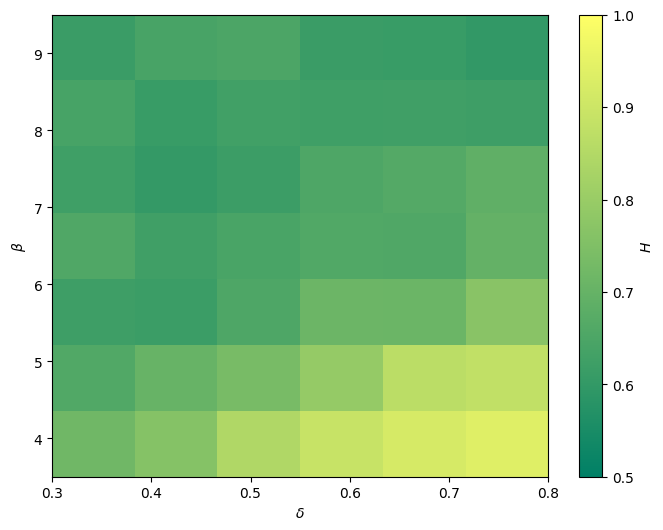

In [16]:
plt.figure(figsize=(8, 6))
entropy_results_mean = np.mean(entropy_results, axis=0)
plt.imshow(entropy_results_mean, origin='lower', extent=[min(delta), max(delta), min(beta), max(beta)],
            aspect='auto', cmap='summer', vmin=0.5, vmax=1)
plt.colorbar(label=r'${H}$')
plt.xlabel(r'$\delta$')  
plt.ylabel(r'$\beta$')

In [17]:
individual_entropy_results = np.zeros((len(policies), len(beta), len(delta)))
individual_entropy_std_results = np.zeros((len(policies), len(beta), len(delta)))
for sim in policies:
    for b in beta:
        for d in delta:

            # 1. Carica il file .npz
            filename = f"entropy/test_results_delta_{d}_beta_{b}_rand_l{sim}.npz"
            data = np.load(filename)
            pos = data['pos']  # Shape: (1000, 330, 2)
    
            # 2. Ultimi 100 time step e primi n individui
            pos_last_100 = pos[-100:, :n]
            num_timesteps, num_ants, _ = pos_last_100.shape
    
            # 3. Entropia di ciascuna formica (formula del paper, celle native 32x32)
            individual_entropies = np.zeros(num_ants)
    
            for i in range(num_ants):
                ant_trajectory = pos_last_100[:, i, :]   # (100, 2)
    
                # V_ij: numero di visite alla cella j (celle uniche = location uniche)
                _, V = np.unique(ant_trajectory, axis=0, return_counts=True)
                k = len(V)
    
                if k > 1:
                    p = V / V.sum()
                    individual_entropies[i] = -np.sum(p * np.log2(p))
                else:
                    # k = 1 -> log(1) = 0, formula indefinita: convenzione D = 0
                    individual_entropies[i] = 0.0
    
            # 4. Media e deviazione standard tra le formiche
            bi, di = beta.index(b), delta.index(d)
            individual_entropy_results[sim, bi, di] = np.mean(individual_entropies)
            individual_entropy_std_results[sim, bi, di] = np.std(individual_entropies)

"for i in range(n_rows):\n  for j in range(n_cols):\n    val = std_entropy[i, j]\n    plt.text(\n        x_centers[j],\n        y_centers[i],\n        f'±{val:.2f}',\n        ha='center',\n        va='center',\n        color='black',\n        fontsize=8,\n    )"

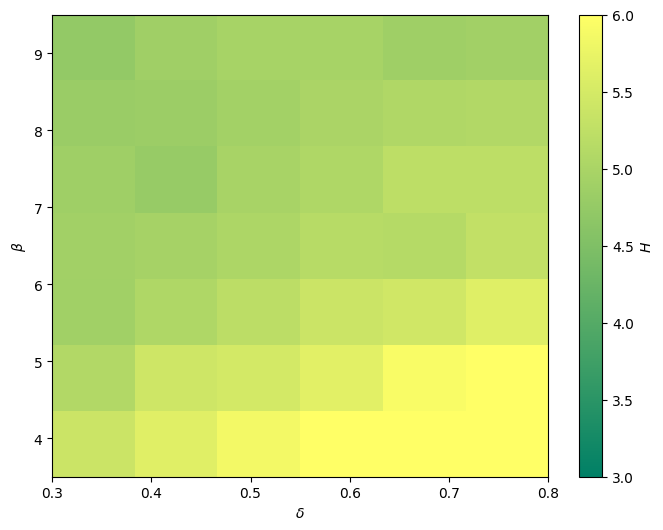

In [ ]:
plt.figure(figsize=(8, 6))
avg_entropy = np.mean(individual_entropy_results, axis=0)
std_entropy = np.std(individual_entropy_results, axis=0)

xmin, xmax = min(delta), max(delta)
ymin, ymax = min(beta), max(beta)

plt.imshow(
    avg_entropy,
    origin='lower',
    extent=[xmin, xmax, ymin, ymax],
    aspect='auto',
    cmap='summer',
    vmin=3,
    vmax=6
)
plt.colorbar(label=r'${H}$')
plt.xlabel(r'$\delta$')
plt.ylabel(r'$\beta$')